In [1]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.documents import Document

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # backend/ 를 import 경로에 추가

from agent import schemas


In [2]:
from datetime import date, datetime

def fundamental(state: schemas.MainState) -> dict:
    return {
        "fundamental_summary": schemas.FundamentalSummary(
            business_overview="(test) 사업 개요",
            stated_risks="(test) 리스크",
            management_outlook="(test) 경영진 전망",
            recent_issues="(test) 최근 이슈",
            sources=[],
        )
    }

def quant(state: schemas.MainState) -> dict:
    snapshot = schemas.QuantSnapshot(
        ticker=state["ticker"],
        market=state["market"],
        as_of_date=state["as_of_date"],
        currency="USD",

        # 기업 정보
        sector="Technology",
        industry="Consumer Electronics",
        market_cap=3.4e12,

        # 가격 / 거래
        price=230.0,
        change_pct=1.2,
        volume=52_000_000,

        # 밸류에이션 / 수익성 (비율은 % 단위)
        per=31.5,
        forward_per=28.0,
        pbr=45.0,
        roe=150.0,
        roa=28.0,
        profit_margin=24.0,
        dividend_yield=None,

        # 기술적 지표 / 모멘텀
        ma_50=225.0,
        ma_200=210.0,
        volatility_60d=22.0,
        return_6m=8.5,
        return_12m=15.0,

        # 컨센서스
        analyst_target_price=None,
        eps_estimate=1.60,
        eps_actual=1.65,
        eps_surprise_pct=3.125,   # (1.65 - 1.60) / 1.60 × 100
    )
    return {"quant_snapshot": snapshot, "quant_summary": "(test) 퀀트 요약"}


# ── 테스트 전환용: True면 과거 결정이 있는 경우, False면 처음 분석하는 경우
HAS_PAST = False


def past_decision(state: schemas.MainState) -> dict:
    """[껍데기] DB에서 해당 종목의 최신 결정을 조회 → PastDecision 또는 None"""
    if not HAS_PAST:
        return {"past_decision": None}

    past_report = schemas.Report(
        investment_thesis="(test) 과거 투자 논리",
        risks="(test) 과거 리스크: 마진 압박 가능성",
        consensus_gap="(test) 과거 컨센서스 차이",
        thesis_breakers="(test) 과거 철회 조건",
        sources=[],
        ticker=state["ticker"],
        market=state["market"],
        as_of_date=date(2026, 7, 20),
        quant_snapshot=schemas.QuantSnapshot(
            ticker=state["ticker"],
            market=state["market"],
            as_of_date=date(2026, 7, 20),
            currency="USD",
            price=210.0,
            per=35.0,
        ),
    )
    highlight = schemas.HighlightGroup(
        id="test-group-1",
        tag="to_verify",
        comment="(test) 다음 분기에 마진 확인",
        spans=[
            schemas.HighlightSpan(
                field="risks",
                start_offset=11,
                end_offset=20,
                quoted_text="마진 압박 가능성",
            )
        ],
    )
    decision = schemas.Decision(
        ticker=state["ticker"],
        market=state["market"],
        decided_at=datetime(2026, 7, 21, 10, 0),
        action="buy",
        weight=0.1,
        confidence=4,
        my_thesis="(test) 내 투자 논리",
        my_thesis_breaker="(test) 데이터센터 매출 성장률 20% 미만",
    )
    return {
        "past_decision": schemas.PastDecision(
            decision=decision,
            report=past_report,
            highlights=[highlight],
            evidence_group_ids=["test-group-1"],
        )
    }


def write_report(state: schemas.MainState) -> dict:
    """[껍데기] fundamental + quant 결과로 리포트 작성. 과거 결정은 보지 않음"""
    draft = schemas.ReportDraft(  # ← 내일 LLM 구조화 출력으로 교체
        investment_thesis="(test) 투자 논리",
        risks="(test) 리스크",
        consensus_gap="(test) 컨센서스 대비 차이",
        thesis_breakers="(test) 철회 조건",
        sources=state["fundamental_summary"].sources,
    )
    report = schemas.Report(
        **draft.model_dump(),
        ticker=state["ticker"],
        market=state["market"],
        as_of_date=state["as_of_date"],
        quant_snapshot=state["quant_snapshot"],
    )
    return {"report": report}


def old_exist(state: schemas.MainState) -> dict:
    """합류 지점. 판단은 route가 하므로 바꾸는 값 없음"""
    return {}


def new_vs_old(state: schemas.MainState) -> dict:
    """[껍데기] 새 리포트 vs 과거 결정 비교 → past_decision_review만 채움"""
    past = state["past_decision"]
    review = schemas.PastDecisionReview(  # ← 내일 LLM 구조화 출력으로 교체
        summary="(test) 과거 대비 변화 요약",
        checks=[
            schemas.PastDecisionCheck(
                category="thesis_breaker",
                target=past.decision.my_thesis_breaker,
                status="not_triggered",
                evidence="(test) 판단 근거",
            )
        ],
    )
    updated = state["report"].model_copy(update={"past_decision_review": review})
    return {"report": updated}


def route(state: schemas.MainState) -> str:
    return "yes" if state.get("past_decision") is not None else "no"


In [3]:
builder = StateGraph(schemas.MainState)

builder.add_node("fundamental", fundamental)
builder.add_node("quant", quant)
builder.add_node("write_report", write_report)
builder.add_node("past_decision", past_decision)
builder.add_node("old_exist", old_exist)
builder.add_node("new_vs_old", new_vs_old)

In [4]:
# fan-out
builder.add_edge(START, "fundamental")
builder.add_edge(START, "quant")
builder.add_edge(START, "past_decision")

# fan-in 1: 펀더멘털 + 퀀트 → 리포트 작성
builder.add_edge(["fundamental", "quant"], "write_report")

# fan-in 2: 리포트 작성 + 과거 결정 → 과거 기록 확인
builder.add_edge(["write_report", "past_decision"], "old_exist")

builder.add_conditional_edges(
    "old_exist",
    route,
    {"yes": "new_vs_old", "no": END},
)
builder.add_edge("new_vs_old", END)

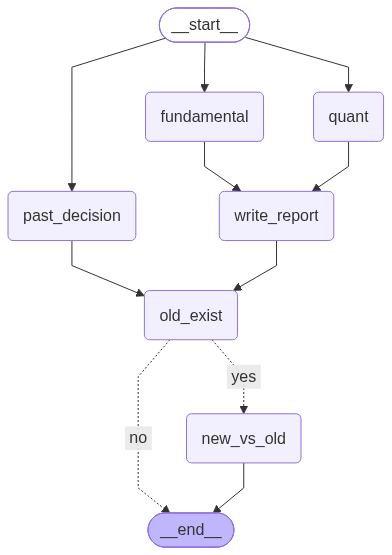

In [5]:
def showGraph(graph):
    # Show the graph
    from IPython.display import Image, display
    display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
    
graph = builder.compile()
showGraph(graph)

In [7]:
result = graph.invoke(inp)
result["report"]

Report(investment_thesis='(test) 투자 논리', risks='(test) 리스크', consensus_gap='(test) 컨센서스 대비 차이', thesis_breakers='(test) 철회 조건', sources=[], ticker='AAPL', market='US', as_of_date=datetime.date(2026, 10, 20), quant_snapshot=QuantSnapshot(ticker='AAPL', market='US', as_of_date=datetime.date(2026, 10, 20), currency='USD', sector='Technology', industry='Consumer Electronics', market_cap=3400000000000.0, price=230.0, change_pct=1.2, volume=52000000, per=31.5, forward_per=28.0, pbr=45.0, roe=150.0, roa=28.0, profit_margin=24.0, dividend_yield=None, ma_50=225.0, ma_200=210.0, volatility_60d=22.0, return_6m=8.5, return_12m=15.0, analyst_target_price=None, eps_estimate=1.6, eps_actual=1.65, eps_surprise_pct=3.125), past_decision_review=PastDecisionReview(summary='(test) 과거 대비 변화 요약', checks=[PastDecisionCheck(category='thesis_breaker', target='(test) 데이터센터 매출 성장률 20% 미만', status='not_triggered', evidence='(test) 판단 근거', sources=[])]))